In [56]:
import re
import json
import pandas as pd
from pathlib import Path

from tqdm import tqdm

In [82]:
DATA_FOLDER = Path("../data")
OUTPUT_FOLDER = Path("../outputs")

In [66]:
def fetch_candidates(df, file: str):
    # Collect all new dataframes in a fast Python list
    new_dfs = []

    for subfolder in tqdm(OUTPUT_FOLDER.iterdir()):
        # Run pattern is '001-...'
        pattern = r"^\d{3}-"
        if not re.search(pattern, subfolder.name):
            print(f"Skipping subfolder {subfolder.name} as it does not match the pattern.")
            continue
        json_file = subfolder / file
        with open(json_file, "r") as f:
            data = json.load(f)

        temp_df = pd.DataFrame(data)
        temp_df["run_name"] = subfolder.name
        new_dfs.append(temp_df)

    if new_dfs:
        return pd.concat([df] + new_dfs, ignore_index=True)

    return df


# Export Relevant Candidates

In [83]:
relevant_candidate_df = pd.DataFrame()
relevant_candidate_df = fetch_candidates(relevant_candidate_df, file="candidate_passages.json")
relevant_candidate_df = relevant_candidate_df.drop_duplicates(subset=["text"]).reset_index(drop=True)
relevant_candidate_df.to_json(DATA_FOLDER / "relevant_candidate_passages.json", orient="records", indent=4, force_ascii=False)

43it [00:00, 891.38it/s]

Skipping subfolder adoption-foreign-countries as it does not match the pattern.
Skipping subfolder free-trade-us as it does not match the pattern.
Skipping subfolder agriculture-subsidies as it does not match the pattern.
Skipping subfolder migrants-worker-criminal as it does not match the pattern.



/tmp/ipykernel_59073/1282224129.py:20: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat([df] + new_dfs, ignore_index=True)


In [85]:
relevant_candidate_df

,corpus_id,rerank_score,speech_id,speaker_id,speaker_first_name,speaker_last_name,speaker_full_name,party,party_name,gender,...,url_api_metadata,url_external_metadata,ideological_summary,statutory_text,source_url,embedding_score,evidence_rank,retrieval_query,topic,run_name
0,3.0,0.627819,318792.0,4062.0,Karin,Keller-Sutter,Karin Keller-Sutter,FDP-Liberale,FDP.Die Liberalen,f,...,https://api.openparldata.ch/v1/affairs/157604,https://www.parlament.ch/de/ratsbetrieb/suche-...,Die Steuerprogression ist ein wesentlicher Gru...,"Der Bundesrat wird beauftragt, der Bundesversa...",,0.818218,1.0,Flatten the progression rates in taxation.,"Public Finances, Taxation",035-svp-flatten-the-progression-rates-in-taxation
1,54.0,0.415577,319615.0,4238.0,Elisabeth,Baume-Schneider,Elisabeth Baume-Schneider,SP,Sozialdemokratische Partei der Schweiz,f,...,https://api.openparldata.ch/v1/affairs/157592,https://www.parlament.ch/de/ratsbetrieb/suche-...,Die Unverjährbarkeitsbestimmung in Artikel 101...,"Der Bundesrat wird beauftragt, eine Änderung d...",,0.788741,1.0,Protect children's sexual integrity from porno...,Criminal Law,007-edu-protect-children-s-sexual-integrity-fr...
2,26.0,0.405891,299873.0,4214.0,Niklaus-Samuel,Gugger,Niklaus-Samuel Gugger,EVP,Evangelische Volkspartei der Schweiz,m,...,https://api.openparldata.ch/v1/affairs/65133,https://www.parlament.ch/de/ratsbetrieb/suche-...,Die Verfügbarkeit und die Verbreitung pornogra...,"Der Bundesrat wird beauftragt, der Bundesversa...",,0.796261,2.0,Protect children's sexual integrity from porno...,Criminal Law,007-edu-protect-children-s-sexual-integrity-fr...
3,55.0,0.592710,248876.0,4052.0,Markus,Ritter,Markus Ritter,CVP,Christlichdemokratische Volkspartei der Schweiz,m,...,https://api.openparldata.ch/v1/affairs/213873,https://www.parlament.ch/de/ratsbetrieb/suche-...,,"Der Bundesrat wird beauftragt, mit der EU Zusa...",,0.795302,1.0,Continue the bilateral path with the EU and pr...,International Affairs,025-bdp-continue-the-bilateral-path-with-the-e...
4,49.0,0.694486,201880.0,172.0,Paul,Rechsteiner,Paul Rechsteiner,SP,Sozialdemokratische Partei der Schweiz,m,...,https://api.openparldata.ch/v1/affairs/53982,https://www.parlament.ch/de/ratsbetrieb/suche-...,Bei Einführung der AHV betrug die durchschnitt...,"Der Bundesrat wird beauftragt, eine gesetzlich...",,0.807845,1.0,Reject raising the AHV retirement age.,Social Welfare,037-lega-reject-raising-the-ahv-retirement-age
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,4.0,0.446660,192499.0,1161.0,Alain,Berset,Alain Berset,SP,Sozialdemokratische Partei der Schweiz,m,...,https://api.openparldata.ch/v1/affairs/212639,https://www.parlament.ch/de/ratsbetrieb/suche-...,Aufgrund der Postulate Fournier 10.3429 und Zu...,"Der Bundesrat wird beauftragt, unnötige Admini...",,0.814911,7.0,Reduce administrative burden and over-regulati...,Economy,011-bdp-reduce-administrative-burden-and-over-...
94,55.0,0.410395,322758.0,1108.0,Guy,Parmelin,Guy Parmelin,SVP,Schweizerische Volkspartei,m,...,https://api.openparldata.ch/v1/affairs/157744,https://www.parlament.ch/de/ratsbetrieb/suche-...,In den letzten Jahrzehnten haben sich in der L...,"Der Bundesrat wird beauftragt, die Gesetzgebun...",,0.790939,8.0,Reduce administrative burden and over-regulati...,Economy,011-bdp-reduce-administrative-burden-and-over-...
95,33.0,0.428836,86144.0,512.0,Simonetta,Sommaruga,Simonetta Sommaruga,SP,Sozialdemokratische Partei der Schweiz,f,...,https://api.openparldata.ch/v1/affairs/209119,https://www.parlament.ch/de/ratsbetrieb/suche-...,"Zahlreiche OECD-Länder haben bzw. sind daran, ...","Der Bundesrat wird eingeladen, im Rahmen der a...",,0.793814,1.0,Reform the withholding tax so that corporate f...,"Finances, Financial Sector",019-fdp-reform-the-withholding-tax-so-that-cor...
96,58.0,0.418482,89101.0,1141.0,Philipp,Müller,Philipp Müller,FDP-Liberale,FDP.Die Liberalen,m,...,https://api.openparldata.ch/v1/affairs/210084,https://www.parl

# Export Non-Relevant Candidates (after deduplication)

In [77]:
non_relevant_candidate_df = pd.DataFrame()
non_relevant_candidate_df = fetch_candidates(non_relevant_candidate_df, file="candidate_passages_before_threshold.json")
non_relevant_candidate_df = non_relevant_candidate_df.drop_duplicates(subset=["text"]).reset_index(drop=True)
non_overlapping_candidate_df = non_relevant_candidate_df[~non_relevant_candidate_df["text"].isin(relevant_candidate_df["text"])].reset_index(drop=True)

43it [00:00, 200.39it/s]

Skipping subfolder adoption-foreign-countries as it does not match the pattern.
Skipping subfolder free-trade-us as it does not match the pattern.
Skipping subfolder agriculture-subsidies as it does not match the pattern.
Skipping subfolder migrants-worker-criminal as it does not match the pattern.


In [105]:
non_overlapping_candidate_df.groupby("language").size()

language
DE    1788
FR    1573
IT     125
dtype: int64

In [106]:
non_overlapping_candidate_df.groupby("topic").size()

topic
(Public) Transportation                          180
Agriculture                                      173
Civil Rights                                     159
Criminal Law                                     192
Culture, Arts, Religion, Sport, Entertainment    186
Economy                                          166
Education, Research                              181
Energy                                           184
Environment                                      185
Finances, Financial Sector                       172
Government Operations                            182
Health                                           179
International Affairs                            188
Labor                                            174
Migration                                        179
National Security, Armed Forces, Defense         168
Parliamentary Procedure                           81
Public Finances, Taxation                        185
Social Welfare                          

In [107]:
non_overlapping_candidate_df.groupby("party").size()

party
BDP              15
CSP               3
CVP             426
EVP              11
FDP-Liberale    593
GLP              54
Grüne           247
LDP               1
Lega             18
MCG              11
Mitte           128
PdA              12
SP              856
SVP             730
parteilos        36
dtype: int64

### Stratified Weighted Candidates Sampling
The reranking_score is used to sample a stratified weighted dataset of candidates. The sampling is done based on the language, topic, and party of the candidates.

I expect the distribution to be very long tailed, with a few candidates having reranking scores close to the threshold while many candidates having reranking scores close to 0.

In [104]:
# Stratified sample per-language, per-topic, per-party
N_PER_GROUP = 1
stratified_weighted_df = (
    non_overlapping_candidate_df
    .groupby(["language", "topic", "party"], group_keys=False)
    .apply(lambda x: x.sample(
        n=min(N_PER_GROUP, len(x)),
        weights=x["rerank_score"], # higher rerank score -> more likely to be sampled (-> edge cases)
        replace=False
    ))
    .reset_index(drop=True)
)

print(f"Stratified sample size: {len(stratified_weighted_df)}")

Stratified sample size: 329


/tmp/ipykernel_59073/30737869.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(


In [126]:
stratified_weighted_df.to_json(DATA_FOLDER / "stratified_non_relevant_candidate_passages.json", orient="records", indent=4, force_ascii=False)

In [108]:
stratified_weighted_df.groupby("language").size()

language
DE    158
FR    129
IT     42
dtype: int64

In [109]:
stratified_weighted_df.groupby("topic").size()

topic
(Public) Transportation                          18
Agriculture                                      15
Civil Rights                                     15
Criminal Law                                     17
Culture, Arts, Religion, Sport, Entertainment    19
Economy                                          16
Education, Research                              18
Energy                                           16
Environment                                      15
Finances, Financial Sector                       16
Government Operations                            11
Health                                           13
International Affairs                            17
Labor                                            16
Migration                                        21
National Security, Armed Forces, Defense         17
Parliamentary Procedure                          17
Public Finances, Taxation                        17
Social Welfare                                   17
Techno

In [110]:
stratified_weighted_df.groupby("party").size()

party
BDP              9
CSP              3
CVP             49
EVP              5
FDP-Liberale    50
GLP             20
Grüne           37
LDP              1
Lega             7
MCG              6
Mitte           27
PdA              6
SP              44
SVP             51
parteilos       14
dtype: int64

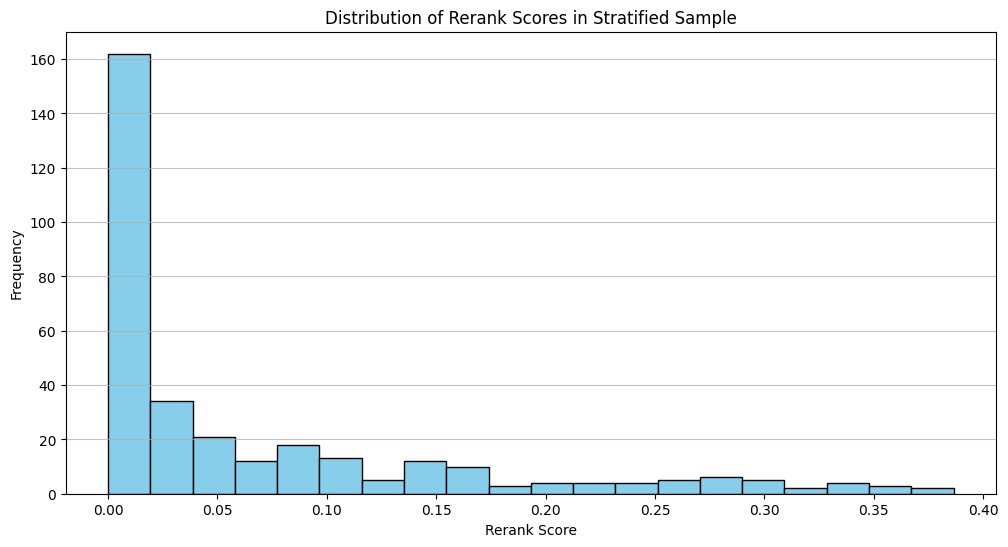

In [125]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.hist(stratified_weighted_df["rerank_score"], bins=20, color='skyblue', edgecolor='black')
plt.title("Distribution of Rerank Scores in Stratified Sample")
plt.xlabel("Rerank Score")
plt.ylabel("Frequency")
plt.grid(axis='y', alpha=0.75)
plt.show()